In [8]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
from matplotlib import font_manager
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
font_manager.fontManager.addfont("../../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})


/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [9]:
def check_nan(adata, name):
    X = adata.X

    if sp.issparse(X):
        nan_count = np.isnan(X.data).sum()
    else:
        nan_count = np.isnan(X).sum()

    print(f"{name} NaN count:", nan_count)

real_data: View of AnnData object with n_obs × n_vars = 600 × 203
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 203
predict_data NaN count: 0
real_data NaN count: 0
r2,pearsonr: 0.7436791932595962 0.8723327605257989
10.0905285 10.130663640418659
10.0905285 10.130663640418659
max 10.130663640418659


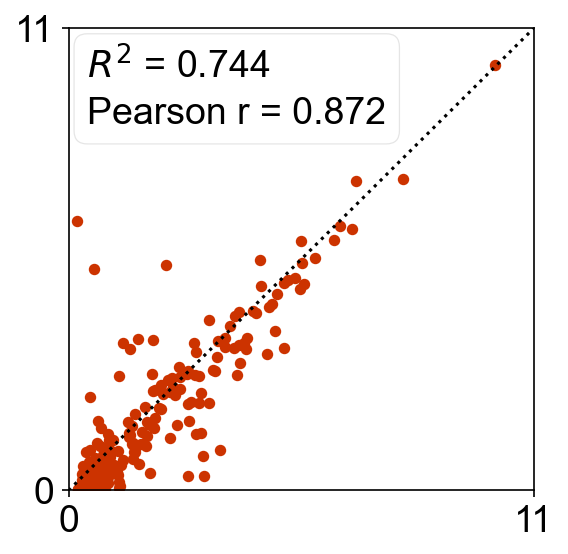

In [10]:

real_data_origin = sc.read_h5ad(f"../../input/diff_test.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==1]
# real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day1/interception_predict_to_day_1.h5ad")
print("predict_data:",predict_data)
check_nan(predict_data, "predict_data")
check_nan(real_data, "real_data")
r2, pearsonr,real,predict= calc_r2_pearson(real_data, predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=150)
plt.scatter(predict,
            real,
            s=20,
            c='#CC3300',
            
            
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
# plt.xlabel(f"Predicted mean expression")
# plt.ylabel(f"Actual mean expression")
ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson r = {pearsonr:.3f}",
      transform=ax.transAxes, va="top", ha="left", fontsize=18, linespacing=1.4,
      bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.5))
fig.savefig(os.path.join(f"day0_predict_day1_compare.pdf"), bbox_inches="tight")


real_data: View of AnnData object with n_obs × n_vars = 600 × 203
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 203
predict_data NaN count: 0
real_data NaN count: 0
r2,pearsonr: 0.743341703566776 0.8965072856830081
9.643981 9.88388605024296
9.643981 9.88388605024296
max 9.88388605024296


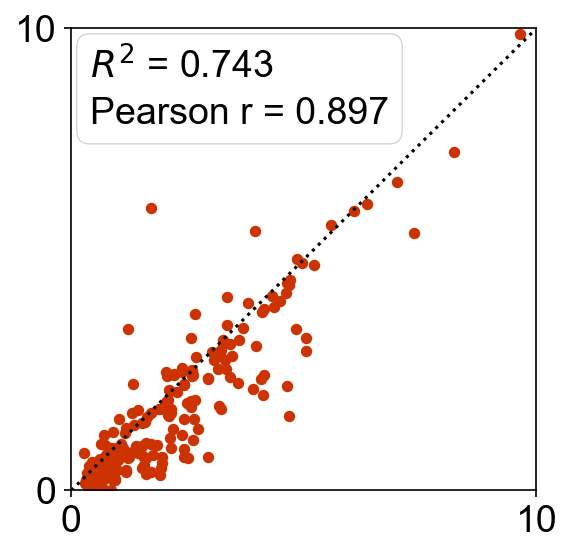

In [11]:

real_data_origin = sc.read_h5ad(f"../../input/diff_test.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==2]
# real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day2/interception_predict_to_day_2.h5ad")
print("predict_data:",predict_data)
check_nan(predict_data, "predict_data")
check_nan(real_data, "real_data")
r2, pearsonr,real,predict= calc_r2_pearson(real_data, predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=150)
plt.scatter(predict,
            real,
            s=20,
            c='#CC3300',
            
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
# plt.xlabel(f"Predicted mean expression")
# plt.ylabel(f"Actual mean expression")
ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson r = {pearsonr:.3f}",
      transform=ax.transAxes, va="top", ha="left", fontsize=18, linespacing=1.4,
      bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day0_predict_day2_compare.pdf"), bbox_inches="tight")


real_data: View of AnnData object with n_obs × n_vars = 600 × 203
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 203
predict_data NaN count: 0
real_data NaN count: 0
r2,pearsonr: 0.9795126820312278 0.9938213610117037
9.241496 9.1570257531213
9.241496 9.1570257531213
max 9.241496


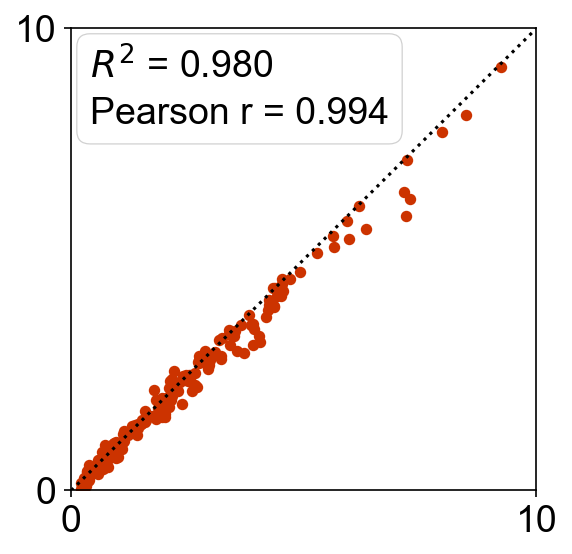

In [12]:

real_data_origin = sc.read_h5ad(f"../../input/diff_test.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==3]
# real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day3/interception_predict_to_day_3.h5ad")
print("predict_data:",predict_data)
check_nan(predict_data, "predict_data")
check_nan(real_data, "real_data")
r2, pearsonr,real,predict= calc_r2_pearson(real_data, predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=150)
plt.scatter(predict,
            real,
            s=20,
            c='#CC3300',
            
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
# plt.xlabel(f"Predicted mean expression")
# plt.ylabel(f"Actual mean expression")
ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson r = {pearsonr:.3f}",
      transform=ax.transAxes, va="top", ha="left", fontsize=18, linespacing=1.4,
      bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"day0_predict_day3_compare.pdf"), bbox_inches="tight")


In [13]:
def clean_adata(adata):
    adata = adata.copy()

    if sp.issparse(adata.X):
        adata.X.data = np.nan_to_num(
            adata.X.data,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )
    else:
        adata.X = np.nan_to_num(
            adata.X,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )

    return adata

real_data: View of AnnData object with n_obs × n_vars = 600 × 203
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 203
predict_data NaN count: 0
real_data NaN count: 0
r2,pearsonr: 0.725311561161395 0.8916716579302931
9.647692050933838 9.88388605024296
9.647692050933838 9.88388605024296
max 9.88388605024296


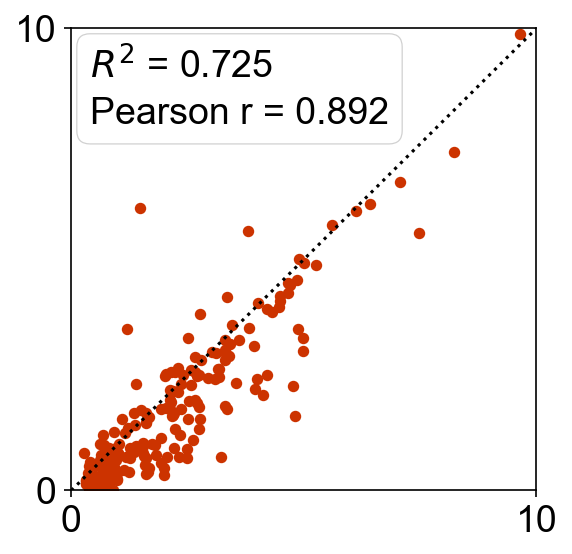

In [14]:

real_data_origin = sc.read_h5ad(f"../../input/diff_test.h5ad")
real_data = real_data_origin[real_data_origin.obs['Group']==2]
# real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad(f"../experiments/exp5_predicted_day1_to_predict_day2/interception_predict_to_day_2.h5ad")
print("predict_data:",predict_data)
predict_data.X = predict_data.X.astype(np.float64)
check_nan(predict_data, "predict_data")
check_nan(real_data, "real_data")
r2, pearsonr,real,predict= calc_r2_pearson(real_data, predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=150)
plt.scatter(predict,
            real,
            s=20,
            c='#CC3300',
            
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 1)
else:    
  ticks = np.arange(0, limit + 1, 100)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
# plt.xlabel(f"Predicted mean expression")
# plt.ylabel(f"Actual mean expression")
ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson r = {pearsonr:.3f}",
      transform=ax.transAxes, va="top", ha="left", fontsize=18, linespacing=1.4,
      bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"predicted_day1_to_predict_day2_compare.pdf"), bbox_inches="tight")
